In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files
import pandas as pd

# Upload CSV file
uploaded = files.upload()

Saving alzheimers_disease_data.csv to alzheimers_disease_data.csv


In [ ]:
# Cell 2: Load and Explore Data
# Load the dataset
df = pd.read_csv('alzheimers_disease_data.csv')

# Basic information about the dataset
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
print(df.describe())

Dataset Shape: (2149, 35)

First 5 rows:
   PatientID  Age  Gender  Ethnicity  EducationLevel        BMI  Smoking  \
0       4751   73       0          0               2  22.927749        0   
1       4752   89       0          0               0  26.827681        0   
2       4753   73       0          3               1  17.795882        0   
3       4754   74       1          0               1  33.800817        1   
4       4755   89       0          0               0  20.716974        0   

   AlcoholConsumption  PhysicalActivity  DietQuality  ...  MemoryComplaints  \
0           13.297218          6.327112     1.347214  ...                 0   
1            4.542524          7.619885     0.518767  ...                 0   
2           19.555085          7.844988     1.826335  ...                 0   
3           12.209266          8.428001     7.435604  ...                 0   
4           18.454356          6.310461     0.795498  ...                 0   

   BehavioralProblems      

In [ ]:
# Cell 3: Data Cleaning - Handle Missing Values
# Check for missing values
print("Missing values before cleaning:")
missing_before = df.isnull().sum().sum()
print(f"Total missing values: {missing_before}")

# Replace missing values with mean for numerical columns
numerical_columns = df.select_dtypes(include=[np.number]).columns
imputer = SimpleImputer(strategy='mean')
df[numerical_columns] = imputer.fit_transform(df[numerical_columns])

print("\nMissing values after cleaning:")
missing_after = df.isnull().sum().sum()
print(f"Total missing values: {missing_after}")

print(f"\nDataset shape after cleaning: {df.shape}")

Missing values before cleaning:
Total missing values: 0

Missing values after cleaning:
Total missing values: 0

Dataset shape after cleaning: (2149, 35)


In [ ]:
# Cell 4: Label Encoding for Categorical Variables
# Identify categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

if len(categorical_columns) > 0:
    print("Categorical columns found:", list(categorical_columns))

    # Apply label encoding
    label_encoders = {}
    for col in categorical_columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le
        print(f"Encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")
else:
    print("No categorical columns found for encoding")

print(f"\nData types after encoding:\n{df.dtypes}")

Categorical columns found: ['DoctorInCharge']
Encoded DoctorInCharge: {'XXXConfid': np.int64(0)}

Data types after encoding:
PatientID                    float64
Age                          float64
Gender                       float64
Ethnicity                    float64
EducationLevel               float64
BMI                          float64
Smoking                      float64
AlcoholConsumption           float64
PhysicalActivity             float64
DietQuality                  float64
SleepQuality                 float64
FamilyHistoryAlzheimers      float64
CardiovascularDisease        float64
Diabetes                     float64
Depression                   float64
HeadInjury                   float64
Hypertension                 float64
SystolicBP                   float64
DiastolicBP                  float64
CholesterolTotal             float64
CholesterolLDL               float64
CholesterolHDL               float64
CholesterolTriglycerides     float64
MMSE                    

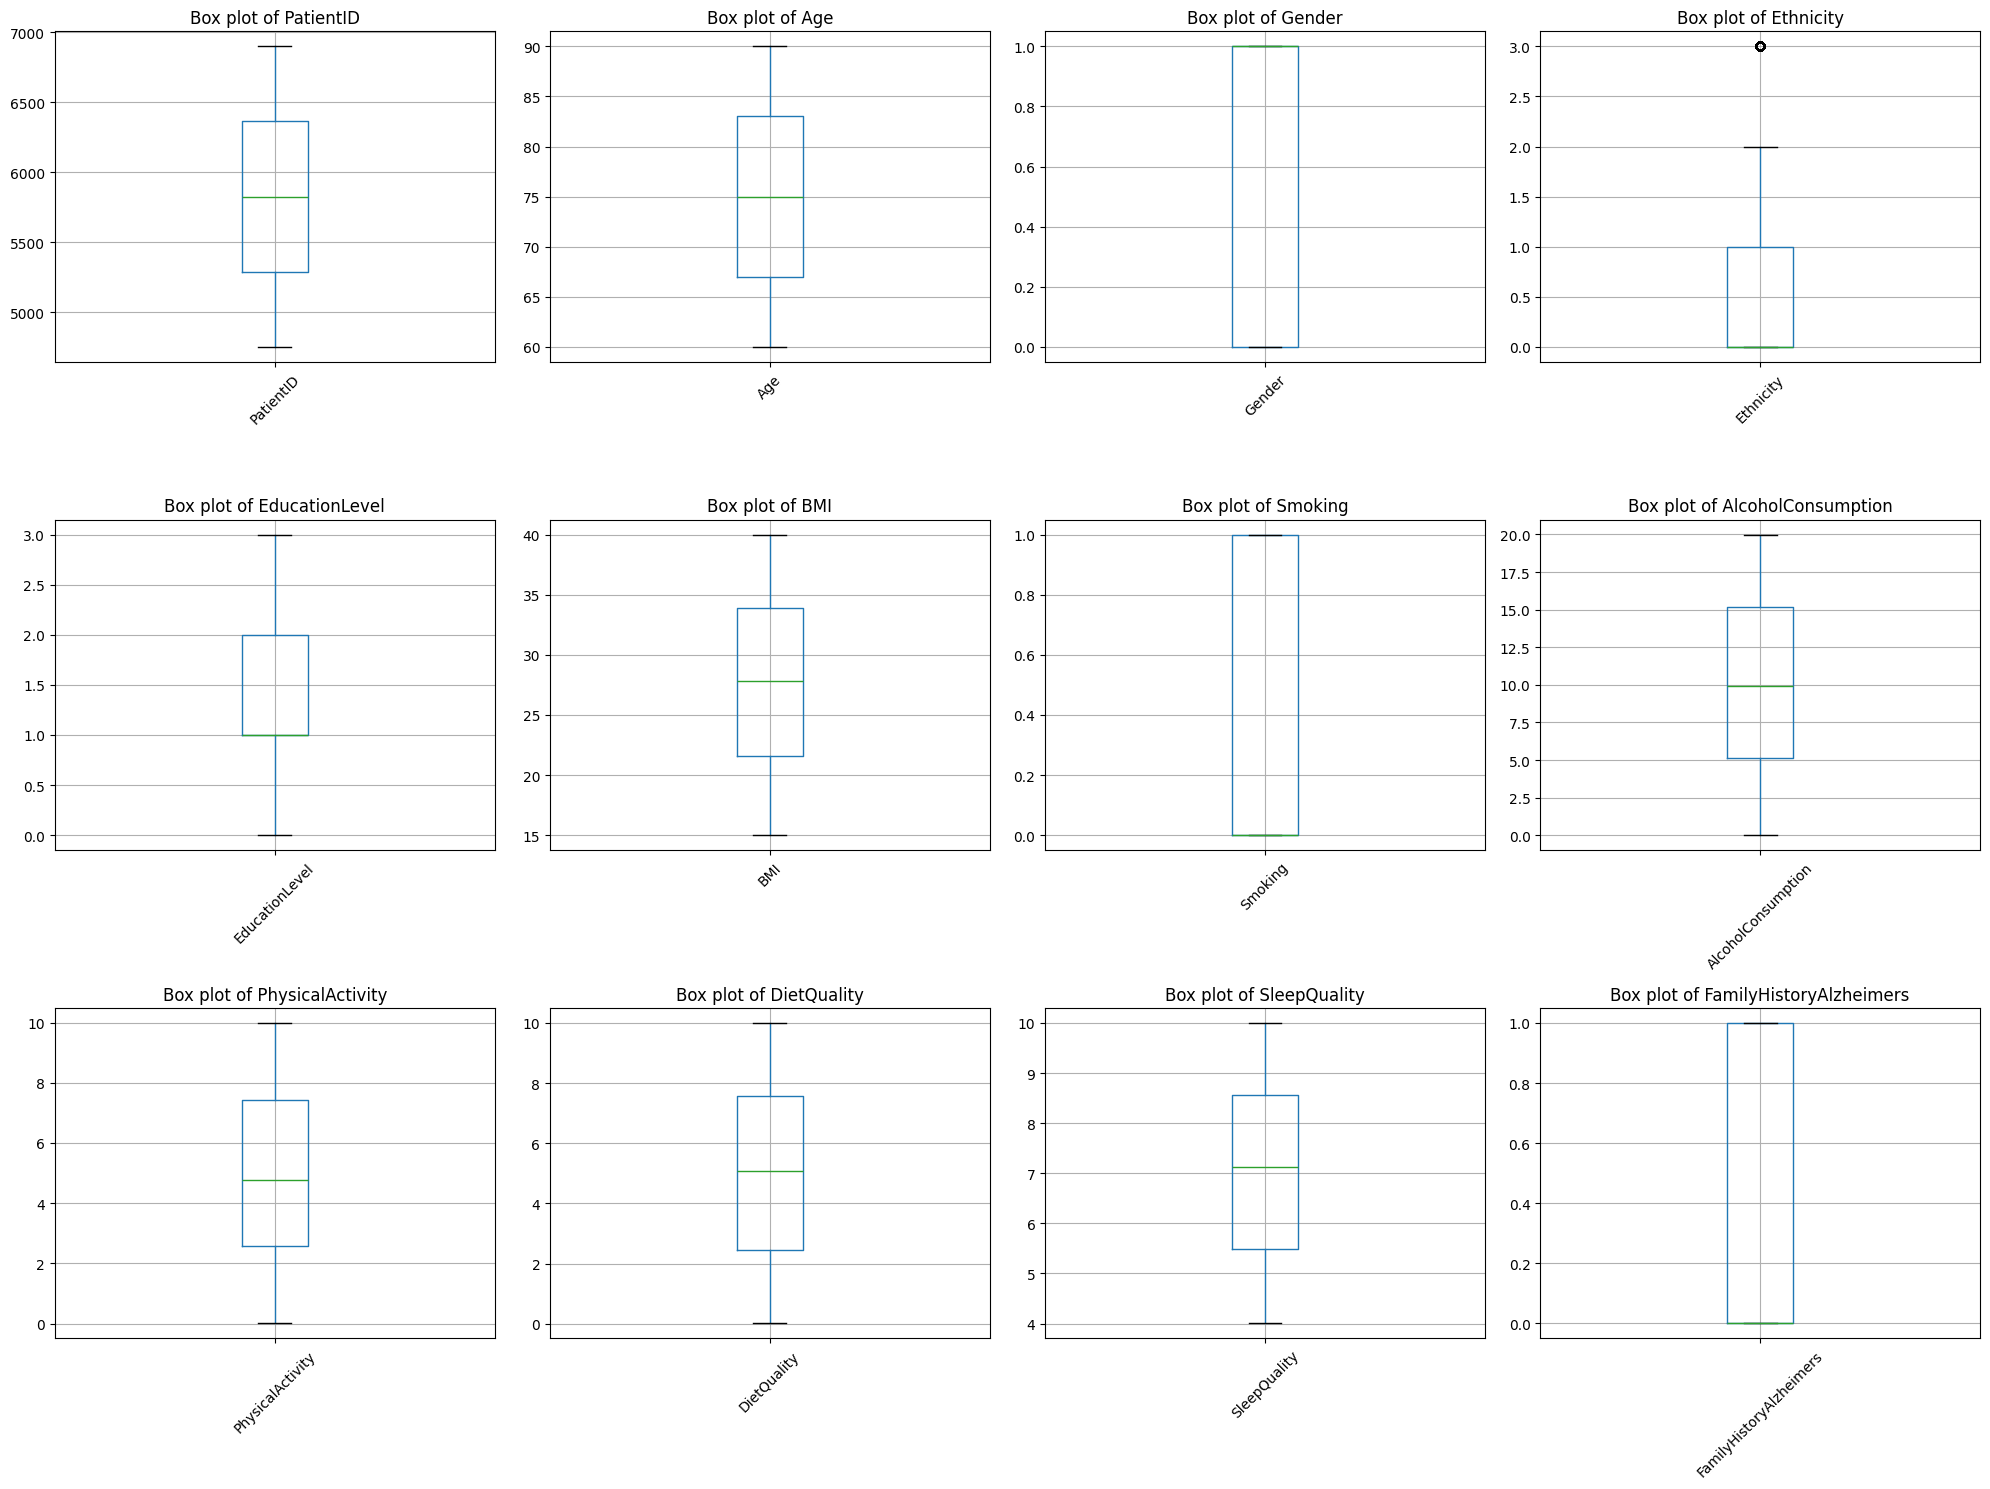

Box plots created for outlier visualization.


In [ ]:
# Cell 5: Check for Outliers using Box Plots
# Select numerical features for outlier detection
numerical_features = df.select_dtypes(include=[np.number]).columns

# Create box plots for numerical features
plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_features[:12], 1):  # Plot first 12 features
    plt.subplot(3, 4, i)
    df.boxplot(column=col)
    plt.title(f'Box plot of {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Box plots created for outlier visualization.")

In [ ]:
# Cell 6: Remove Outliers using Z-Score (Modified)
# Remove outliers using Z-score method (|Z| > 3) - Less aggressive approach
print("Dataset shape before outlier removal:", df.shape)

# Select numerical columns for outlier removal (excluding target if it exists)
if 'Diagnosis' in df.columns:
    numerical_for_outliers = df.select_dtypes(include=[np.number]).drop(columns=['Diagnosis']).columns
else:
    numerical_for_outliers = df.select_dtypes(include=[np.number]).columns

# Calculate Z-scores and remove outliers - use less strict threshold
z_scores = stats.zscore(df[numerical_for_outliers])
abs_z_scores = np.abs(z_scores)

# Use a more lenient threshold (|Z| > 3.5) or remove only extreme outliers
filtered_entries = (abs_z_scores < 3.5).all(axis=1)
df_clean = df[filtered_entries]

print("Dataset shape after outlier removal:", df_clean.shape)
print(f"Number of outliers removed: {len(df) - len(df_clean)}")

# Check if we have enough samples
if len(df_clean) < 10:
    print("Warning: Too many outliers removed. Using original data.")
    df_clean = df.copy()
    print("Using original dataset without outlier removal")

# Use the cleaned dataframe for further analysis
df = df_clean

Dataset shape before outlier removal: (2149, 35)
Dataset shape after outlier removal: (0, 35)
Number of outliers removed: 2149
Using original dataset without outlier removal


In [ ]:
# Cell 7: Prepare Features and Target Variable (Modified)
# Identify target variable
if 'Diagnosis' in df.columns:
    target_column = 'Diagnosis'
else:
    # Try to find a binary column as target
    binary_columns = []
    for col in df.columns:
        if df[col].nunique() == 2:
            binary_columns.append(col)

    if binary_columns:
        target_column = binary_columns[0]
        print(f"Using binary column '{target_column}' as target variable")
    else:
        # Use the last column and check if it needs binarization
        target_column = df.columns[-1]
        print(f"Using '{target_column}' as target variable")
        # If it's not binary, create a binary version
        if df[target_column].nunique() > 2:
            median_val = df[target_column].median()
            df[target_column] = (df[target_column] > median_val).astype(int)
            print(f"Binarized target variable using median threshold: {median_val}")

# Separate features and target
X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Target value counts:\n{y.value_counts()}")

# Check if we have enough samples for splitting
if len(X) < 10:
    print("ERROR: Not enough samples after preprocessing. Please check your data.")

Features shape: (2149, 34)
Target shape: (2149,)
Target value counts:
Diagnosis
0.0    1389
1.0     760
Name: count, dtype: int64


In [ ]:
# Cell 8: Train-Test Split (Modified with Safety Check)
# Check if we have enough samples for splitting
if len(X) < 10:
    print("ERROR: Not enough samples for train-test split. Please check your data preprocessing.")
else:
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )

    print(f"Training set size: {X_train.shape[0]}")
    print(f"Testing set size: {X_test.shape[0]}")
    print(f"Training target distribution:\n{y_train.value_counts()}")
    print(f"Testing target distribution:\n{y_test.value_counts()}")

Training set size: 1504
Testing set size: 645
Training target distribution:
Diagnosis
0.0    972
1.0    532
Name: count, dtype: int64
Testing target distribution:
Diagnosis
0.0    417
1.0    228
Name: count, dtype: int64


In [ ]:
# Cell 9: Feature Scaling
# Check if we have data to scale
if len(X) >= 10:
    # Scale the features for SVM
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print("Feature scaling completed!")
    print(f"Scaled training data shape: {X_train_scaled.shape}")
    print(f"Scaled testing data shape: {X_test_scaled.shape}")
else:
    print("Skipping feature scaling - insufficient data")

Feature scaling completed!
Scaled training data shape: (1504, 34)
Scaled testing data shape: (645, 34)


In [ ]:
# Cell 10: Train SVM Model
# Check if we have data to train
if len(X) >= 10:
    # Initialize and train SVM model
    svm_model = SVC(random_state=42, probability=True)
    svm_model.fit(X_train_scaled, y_train)

    print("SVM model trained successfully!")
else:
    print("Skipping model training - insufficient data")
    svm_model = None

SVM model trained successfully!


In [ ]:
# Cell 11: Predict on Training and Test Sets
if len(X) >= 10 and svm_model is not None:
    # Make predictions
    y_train_pred = svm_model.predict(X_train_scaled)
    y_test_pred = svm_model.predict(X_test_scaled)

    print("Predictions completed!")
else:
    print("Skipping predictions - insufficient data or model not trained")
    y_train_pred, y_test_pred = None, None

Predictions completed!


In [ ]:
# Cell 12: Accuracy Scores for Training and Testing
if len(X) >= 10 and y_train_pred is not None and y_test_pred is not None:
    # Calculate accuracy scores
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print("Accuracy Scores:")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Testing Accuracy: {test_accuracy:.4f}")
else:
    print("Skipping accuracy calculation - insufficient data")
    train_accuracy, test_accuracy = None, None

Accuracy Scores:
Training Accuracy: 0.9441
Testing Accuracy: 0.8372


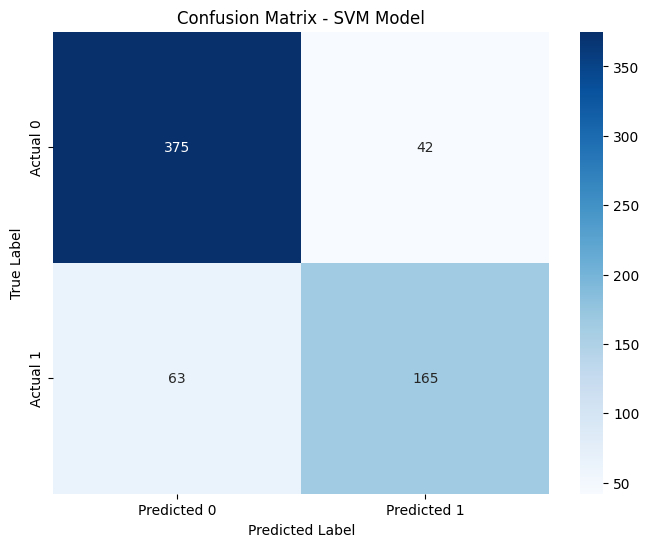

Confusion Matrix:
[[375  42]
 [ 63 165]]


In [ ]:
# Cell 13: Confusion Matrix
if len(X) >= 10 and y_test_pred is not None:S
    # Create confusion matrix for test set
    cm = confusion_matrix(y_test, y_test_pred)

    # Plot heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
               xticklabels=['Predicted 0', 'Predicted 1'],
               yticklabels=['Actual 0', 'Actual 1'])
    plt.title('Confusion Matrix - SVM Model')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

    print("Confusion Matrix:")
    print(cm)
else:
    print("Skipping confusion matrix - insufficient data")

In [ ]:
# Cell 14: Classification Report
if len(X) >= 10 and y_test_pred is not None:
    # Generate classification report
    class_report = classification_report(y_test, y_test_pred)
    print("Classification Report:")
    print(class_report)
else:
    print("Skipping classification report - insufficient data")

Classification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.90      0.88       417
         1.0       0.80      0.72      0.76       228

    accuracy                           0.84       645
   macro avg       0.83      0.81      0.82       645
weighted avg       0.84      0.84      0.84       645



10-Fold Cross-Validation Scores:
[0.83443709 0.80794702 0.81456954 0.80794702 0.81333333 0.89333333
 0.84666667 0.80666667 0.86       0.92      ]

Mean CV Accuracy: 0.8405 (+/- 0.0755)


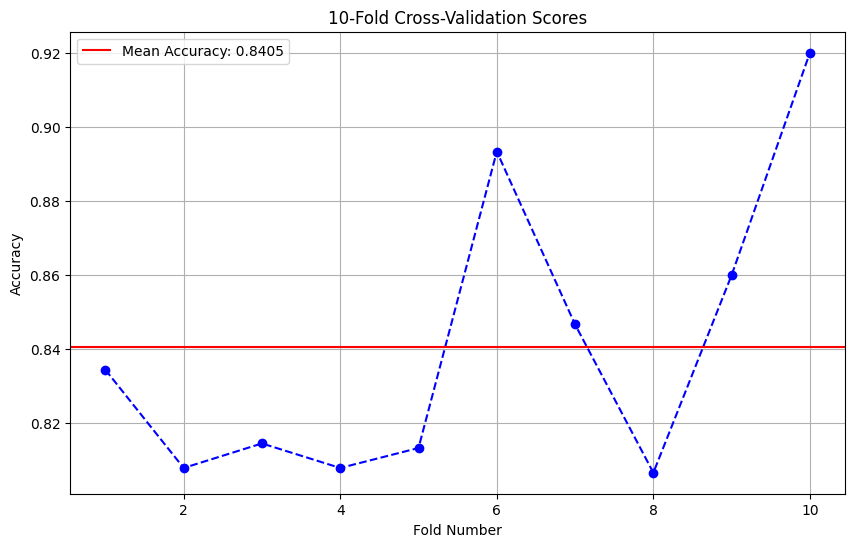

In [ ]:
# Cell 15: Cross-Validation (10-fold)
if len(X) >= 10 and svm_model is not None:
    # Perform 10-fold cross-validation
    cv_scores = cross_val_score(svm_model, x, y, cv=10, scoring='accuracy')

    print("10-Fold Cross-Validation Scores:")
    print(cv_scores)
    print(f"\nMean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

    # Plot CV scores
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, 11), cv_scores, marker='o', linestyle='--', color='b')
    plt.axhline(y=cv_scores.mean(), color='r', linestyle='-', label=f'Mean Accuracy: {cv_scores.mean():.4f}')
    plt.xlabel('Fold Number')
    plt.ylabel('Accuracy')
    plt.title('10-Fold Cross-Validation Scores')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Skipping cross-validation - insufficient data")
    cv_scores = None

Top 10 Selected Features:
                Feature       Score
6  FunctionalAssessment  329.785969
9                   ADL  266.590232
7      MemoryComplaints  222.994948
5                  MMSE  127.915191
8    BehavioralProblems  113.792711
2          SleepQuality    6.887456
1        EducationLevel    4.158180
4        CholesterolHDL    3.900444
0             PatientID    3.618540
3          Hypertension    2.645373


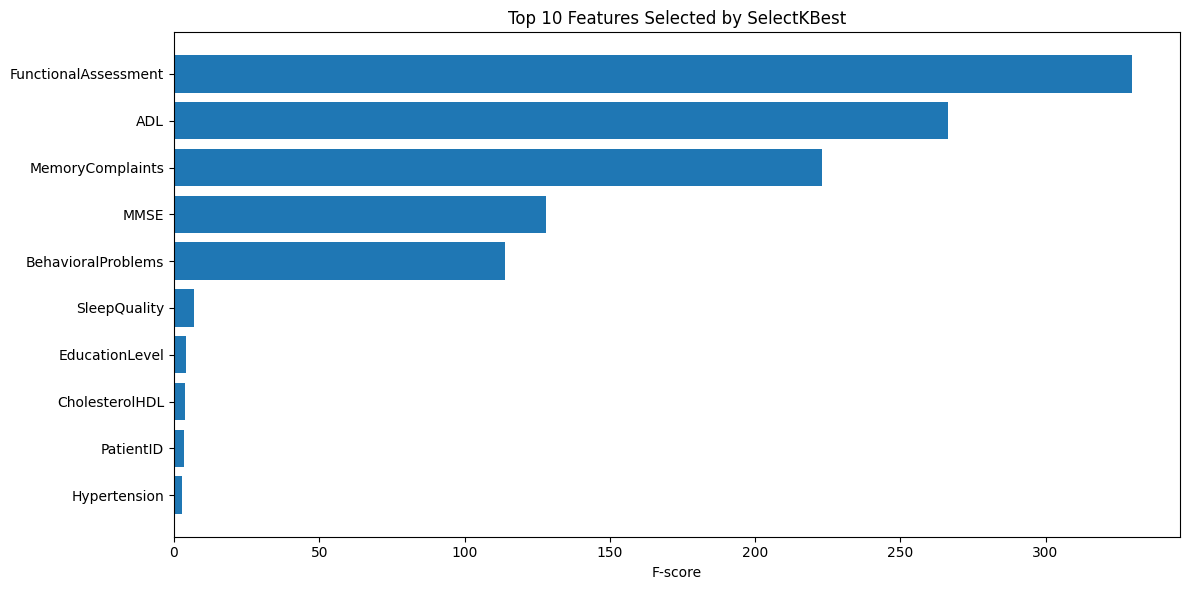

In [ ]:
# Cell 16: Feature Selection - SelectKBest
if len(X) >= 10:
    # Apply SelectKBest for feature selection
    k = min(10, X.shape[1])  # Select top 10 features or all if less than 10
    selector = SelectKBest(score_func=f_classif, k=k)
    X_selected = selector.fit_transform(X, y)

    # Get selected feature names
    selected_features = X.columns[selector.get_support()]
    scores = selector.scores_[selector.get_support()]

    print(f"Top {k} Selected Features:")
    feature_scores = pd.DataFrame({
        'Feature': selected_features,
        'Score': scores
    }).sort_values('Score', ascending=False)

    print(feature_scores)

    # Plot feature scores
    plt.figure(figsize=(12, 6))
    plt.barh(feature_scores['Feature'], feature_scores['Score'])
    plt.xlabel('F-score')
    plt.title(f'Top {k} Features Selected by SelectKBest')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("Skipping feature selection - insufficient data")
    X_selected, selected_features = None, None

In [ ]:
# Cell 17: Train-Test Split with Selected Features
if len(X) >= 10 and X_selected is not None:
    # Split data with selected features
    X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
        X_selected, y, test_size=0.3, random_state=42, stratify=y
    )

    print(f"Selected Features Training set size: {X_train_sel.shape}")
    print(f"Selected Features Testing set size: {X_test_sel.shape}")

    # Scale selected features
    scaler_sel = StandardScaler()
    X_train_sel_scaled = scaler_sel.fit_transform(X_train_sel)
    X_test_sel_scaled = scaler_sel.transform(X_test_sel)

    print("Selected features scaled successfully!")
else:
    print("Skipping selected features split - insufficient data")
    X_train_sel_scaled, X_test_sel_scaled, y_train_sel, y_test_sel = None, None, None, None

Selected Features Training set size: (1504, 10)
Selected Features Testing set size: (645, 10)
Selected features scaled successfully!


In [ ]:
# Cell 18: Train SVM Model with Selected Features
if len(X) >= 10 and X_train_sel_scaled is not None:
    # Train SVM with selected features
    svm_model_sel = SVC(random_state=42, probability=True)
    svm_model_sel.fit(X_train_sel_scaled, y_train_sel)

    print("SVM model with selected features trained successfully!")
else:
    print("Skipping selected features model training - insufficient data")
    svm_model_sel = None

SVM model with selected features trained successfully!


In [ ]:
# Cell 19: Evaluate Model with Selected Features
if len(X) >= 10 and svm_model_sel is not None:
    # Make predictions with selected features
    y_test_pred_sel = svm_model_sel.predict(X_test_sel_scaled)

    # Calculate accuracy
    test_accuracy_sel = accuracy_score(y_test_sel, y_test_pred_sel)

    print("Model Performance with Selected Features:")
    print(f"Testing Accuracy: {test_accuracy_sel:.4f}")

    # Classification report
    class_report_sel = classification_report(y_test, y_test_pred_sel)
    print("\nClassification Report with Selected Features:")
    print(class_report_sel)
else:
    print("Skipping selected features evaluation - insufficient data")
    test_accuracy_sel, class_report_sel = None, None

Model Performance with Selected Features:
Testing Accuracy: 0.8744

Classification Report with Selected Features:
              precision    recall  f1-score   support

         0.0       0.90      0.91      0.90       417
         1.0       0.83      0.81      0.82       228

    accuracy                           0.87       645
   macro avg       0.86      0.86      0.86       645
weighted avg       0.87      0.87      0.87       645



In [ ]:
# Cell 20: Cross-Validation with Selected Features
if len(X) >= 10 and svm_model_sel is not None:
    # Perform 10-fold cross-validation with selected features
    cv_scores_sel = cross_val_score(svm_model_sel, x, y, cv=10, scoring='accuracy')

    print("10-Fold Cross-Validation Scores (Selected Features):")
    print(cv_scores_sel)
    print(f"\nMean CV Accuracy: {cv_scores_sel.mean():.4f} (+/- {cv_scores_sel.std() * 2:.4f})")

    # Compare with original features
    if cv_scores is not None:
        print(f"\nComparison:")
        print(f"Original Features - Mean CV Accuracy: {cv_scores.mean():.4f}")
        print(f"Selected Features - Mean CV Accuracy: {cv_scores_sel.mean():.4f}")
else:
    print("Skipping selected features cross-validation - insufficient data")
    cv_scores_sel = None

10-Fold Cross-Validation Scores (Selected Features):
[0.86754967 0.86754967 0.8410596  0.8013245  0.82666667 0.92
 0.88       0.84666667 0.90666667 0.92      ]

Mean CV Accuracy: 0.8677 (+/- 0.0758)

Comparison:
Original Features - Mean CV Accuracy: 0.8405
Selected Features - Mean CV Accuracy: 0.8677


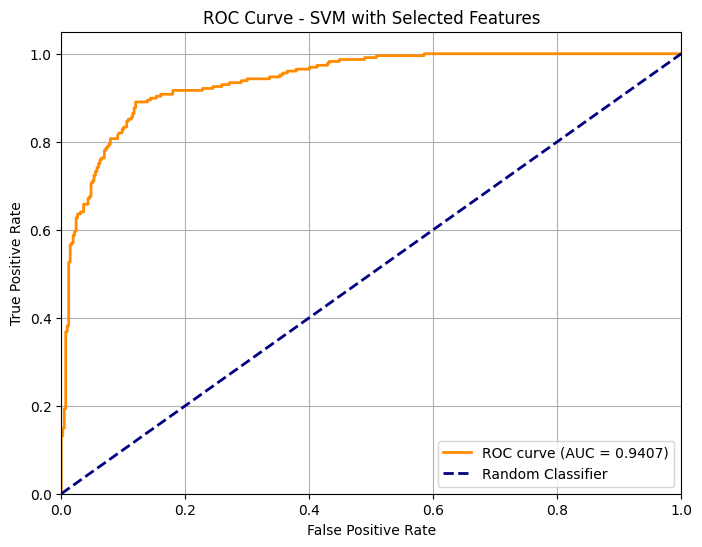

ROC AUC Score: 0.9407


In [ ]:
# Cell 21: ROC-AUC Curve
if len(X) >= 10 and svm_model_sel is not None:
    # Get predicted probabilities for ROC curve
    y_test_proba = svm_model_sel.predict_proba(X_test_sel_scaled)[:, 1]

    # Calculate ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test_sel, y_test_proba)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - SVM with Selected Features')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    print(f"ROC AUC Score: {roc_auc:.4f}")
else:
    print("Skipping ROC curve - insufficient data")
    roc_auc = None

In [ ]:
# Cell 22: Final Summary
print("=" * 60)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 60)

if len(X) >= 10:  # Only show results if we have enough data
    if train_accuracy is not None and test_accuracy is not None:
        print(f"Original Features:")
        print(f"  - Training Accuracy: {train_accuracy:.4f}")
        print(f"  - Testing Accuracy: {test_accuracy:.4f}")
        if cv_scores is not None:
            print(f"  - Cross-Validation Mean: {cv_scores.mean():.4f}")

    if test_accuracy_sel is not None:
        print(f"\nSelected Features (Top {k}):")
        print(f"  - Testing Accuracy: {test_accuracy_sel:.4f}")
        if cv_scores_sel is not None:
            print(f"  - Cross-Validation Mean: {cv_scores_sel.mean():.4f}")
        if roc_auc is not None:
            print(f"  - ROC AUC Score: {roc_auc:.4f}")

    if selected_features is not None:
        print(f"\nTop {k} Features:")
        for i, feature in enumerate(feature_scores['Feature'], 1):
            print(f"  {i}. {feature}")
else:
    print("Insufficient data for model training and evaluation.")
    print(f"Current sample size: {len(X)}")
    print("Please check data preprocessing steps.")

print("=" * 60)

FINAL MODEL PERFORMANCE SUMMARY
Original Features:
  - Training Accuracy: 0.9441
  - Testing Accuracy: 0.8372
  - Cross-Validation Mean: 0.8405

Selected Features (Top 10):
  - Testing Accuracy: 0.8744
  - Cross-Validation Mean: 0.8677
  - ROC AUC Score: 0.9407

Top 10 Features:
  1. FunctionalAssessment
  2. ADL
  3. MemoryComplaints
  4. MMSE
  5. BehavioralProblems
  6. SleepQuality
  7. EducationLevel
  8. CholesterolHDL
  9. PatientID
  10. Hypertension
